# Modelos explicables: ¿qué separa un cráter de la Luna, de Marte y de la Tierra?

<a href="https://colab.research.google.com/github/Niettzche/spaceapps-2026/blob/main/ciencia_datos/01_modelos_explicables.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

**Pregunta.** Con las medidas que el detector saca de cada cráter (mismo código, 200 m por píxel en los tres cuerpos), ¿qué reglas simples distinguen Luna, Marte y Tierra? ¿Y qué cráteres de México se parecen tanto a los lunares o marcianos que un modelo los confunde?

**Por qué modelos explicables y no redes neuronales.** Tenemos pocos cráteres terrestres confiables (decenas). Una red memorizaría. Además el reto pide justificar la analogía y decir dónde se rompe; para eso sirve un modelo cuyas reglas se pueden leer.

**Plan**
1. Carga y preprocesamiento (qué variables, qué se descarta y por qué).
2. Visualización: cómo se ve cada cuerpo y el problema de las detecciones en zonas húmedas (hoyos reales que no son cráteres).
3. Validación honesta: grupos espaciales, no partición al azar.
4. Modelos: árbol de decisión poco profundo y regresión logística, contra una línea base.
5. Experimento de control: qué aprende el modelo si se usan las 668 detecciones de México (con las de zonas húmedas).
6. Puntaje de análogo fuera de pliegue para los cráteres de México.
7. Conclusiones y límites.

Datos: `ciencia_datos/datos/crateres_mexico.csv` y `ciencia_datos/datos/hoyas_referencia.csv` (copia de `respaldo/web_data`, que no está en git), generados por `analisis/07_buscador_crateres.py` y `08_validacion.py`.

In [1]:
# Carga de datos: funciona local (repo clonado) y en Colab (repo privado: usa un token de GitHub en los secretos de Colab)
import os, io, json, subprocess
from pathlib import Path

REPO = "Niettzche/spaceapps-2026"
RUTA = "ciencia_datos/datos"
ARCHIVOS = ["crateres_mexico.csv", "hoyas_referencia.csv"]

def encontrar_raiz():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / RUTA / ARCHIVOS[0]).exists():
            return p
    return None

RAIZ = encontrar_raiz()
if RAIZ is None:                          # Colab: clonar el repo con el token guardado como secreto GITHUB_TOKEN
    try:
        from google.colab import userdata
        tok = userdata.get("GITHUB_TOKEN")
        url = f"https://{tok}@github.com/{REPO}.git"
    except Exception:
        url = f"https://github.com/{REPO}.git"
    subprocess.run(["git", "clone", "--depth", "1", url, "/content/spaceapps-2026"], check=True)
    RAIZ = Path("/content/spaceapps-2026")
DATOS = RAIZ / RUTA
SALIDA = RAIZ / "ciencia_datos" / "salidas"; SALIDA.mkdir(parents=True, exist_ok=True)
print("Datos en", DATOS)

Datos en /home/mario/spaceapps-2026/ciencia_datos/datos


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.inspection import permutation_importance

SEMILLA = 0
COLORES = {"Luna": "#8a8f98", "Marte": "#b5532f", "Tierra": "#1f6f78"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

mx = pd.read_csv(DATOS / "crateres_mexico.csv")
ref = pd.read_csv(DATOS / "hoyas_referencia.csv")
print("México:", mx.shape, "| Referencia Luna+Marte:", ref.shape)

México: (668, 35) | Referencia Luna+Marte: (7170, 16)


## 1. Preprocesamiento

**Filtrado.** Solo depresiones que pasan `tipo_crater()` (0.6–10 km, ≥ 20 m de profundidad, circularidad ≥ 0.6). México ya viene filtrado; en la referencia hay que aplicarlo.

**Variables que usamos** (todas medidas igual en los tres cuerpos):

| Variable | Qué es | Transformación |
|---|---|---|
| `log_diam` | diámetro (km) | log10, porque va de 0.6 a 10 km |
| `prof_diam` | profundidad / diámetro (d/D) | ninguna; es el rasgo clásico de frescura de un cráter |
| `borde_rel` | altura del borde / diámetro | se normaliza por tamaño para que no repita al diámetro |
| `relleno` | qué tanto llena la hoya su caja | ninguna |
| `aspecto` | lado corto / lado largo de la caja | ninguna |

**Variables que descartamos**
- `elev_m`: cada cuerpo tiene su propio nivel de referencia. El modelo separaría por ahí sin aprender geología (fuga de información).
- `area_px`, `diam_km` crudo: redundantes con `log_diam`.
- `circ`: es `relleno × aspecto`; ya están las dos.
- `prof_m` cruda: es `prof_diam × diámetro`.
- `ndvi_p90`, `albedo`, `km_mina`, etc.: solo existen para México. Sirven para limpiar, no para clasificar.

**Etiqueta Tierra.** De las 668 detecciones de México, 472 están en selva (NDVI > 0.7) y casi ninguna es un cráter. No son un error del modelo de elevación: con FABDEM (Copernicus sin árboles ni edificios) las detecciones en esas zonas bajan solo 15 %. Son **depresiones reales del terreno, no cráteres**: dolinas de sierras kársticas y cañadas cerradas de terreno muy disectado que, a 200 m por píxel, cumplen las reglas de forma del detector. Mientras el equipo no revise a mano, usamos como Tierra solo las detecciones en **zonas áridas (NDVI p90 < 0.35)**: 47 casos. Siguen teniendo ruido (según la revisión preliminar, unas 14 son cráteres o minas reales), así que lo tratamos como un primer paso.

In [3]:
UMBRAL_NDVI = 0.35
FEATS = ["log_diam", "prof_diam", "borde_rel", "relleno", "aspecto"]
NOMBRES = {"log_diam": "log10 diámetro (km)", "prof_diam": "profundidad / diámetro", "borde_rel": "borde / diámetro",
           "relleno": "relleno", "aspecto": "aspecto"}

def preparar(d):
    d = d.copy()
    d["log_diam"] = np.log10(d.diam_km)
    d["borde_rel"] = d.borde_m / (d.diam_km * 1000)
    return d

# Grupos espaciales para validar: bloques de ~50 km, para que cráteres vecinos no queden a la vez en entrenamiento y prueba
r = preparar(ref[ref.crater].copy())
r["grupo"] = r.cuerpo + "|" + r.sitio + "|" + (r.i // 250).astype(int).astype(str) + "_" + (r.j // 250).astype(int).astype(str)
m = preparar(mx.copy())
m["cuerpo"] = "Tierra"; m["sitio"] = "México"
m["grupo"] = "Tierra|" + m.br.astype(str) + "_" + m.bc.astype(str)
m["arida"] = m.ndvi_p90 < UMBRAL_NDVI
m["entorno"] = pd.cut(m.ndvi_p90, [0, UMBRAL_NDVI, 0.7, 1], labels=["árido", "intermedio", "selva"])

print("Valores faltantes en las variables:", int(r[FEATS].isna().sum().sum() + m[FEATS].isna().sum().sum()))
print("\nCráteres por cuerpo y sitio (referencia):"); print(r.groupby(["cuerpo", "sitio"]).size().to_string())
print("\nMéxico por entorno:"); print(m.entorno.value_counts().sort_index().to_string())
print("\nMéxico árido por tipo:"); print(m[m.arida].tipo.value_counts().to_string())
print("\nGrupos espaciales:", r.groupby("cuerpo").grupo.nunique().to_dict(), "| México árido:", m[m.arida].grupo.nunique())

Valores faltantes en las variables: 0

Cráteres por cuerpo y sitio (referencia):
cuerpo  sitio             
Luna    Anillo 80-85°S        3232
        Polo sur (85-90°S)    1056
Marte   Cráter Gale             90
        Cráter Jezero          104
        Oxia Planum             90

México por entorno:
entorno
árido          47
intermedio    149
selva         472

México árido por tipo:
tipo
sin_borde    33
mina         10
con_borde     4

Grupos espaciales: {'Luna': 140, 'Marte': 12} | México árido: 23


In [4]:
# Conjunto de modelado principal: Luna + Marte + Tierra árida
cols = FEATS + ["cuerpo", "sitio", "grupo"]
datos = pd.concat([r[cols], m.loc[m.arida, cols + ["cid", "nombre", "tipo"]]], ignore_index=True)
X = datos[FEATS].to_numpy(float); y = datos.cuerpo.to_numpy(object); g = datos.grupo.to_numpy(object)
print(datos.cuerpo.value_counts().to_string())
print("\nResumen por cuerpo (medianas):")
print(datos.groupby("cuerpo")[FEATS].median().round(3).to_string())

cuerpo
Luna      4288
Marte      284
Tierra      47

Resumen por cuerpo (medianas):
        log_diam  prof_diam  borde_rel  relleno  aspecto
cuerpo                                                  
Luna       0.004      0.060     -0.018    0.955    0.867
Marte      0.061      0.027     -0.012    0.935    0.850
Tierra    -0.031      0.034     -0.005    0.849    0.867


## 2. Visualización

Primero, cómo se reparten las variables en cada cuerpo. Las curvas están normalizadas para que la Luna (miles de cráteres) no tape a la Tierra (decenas).

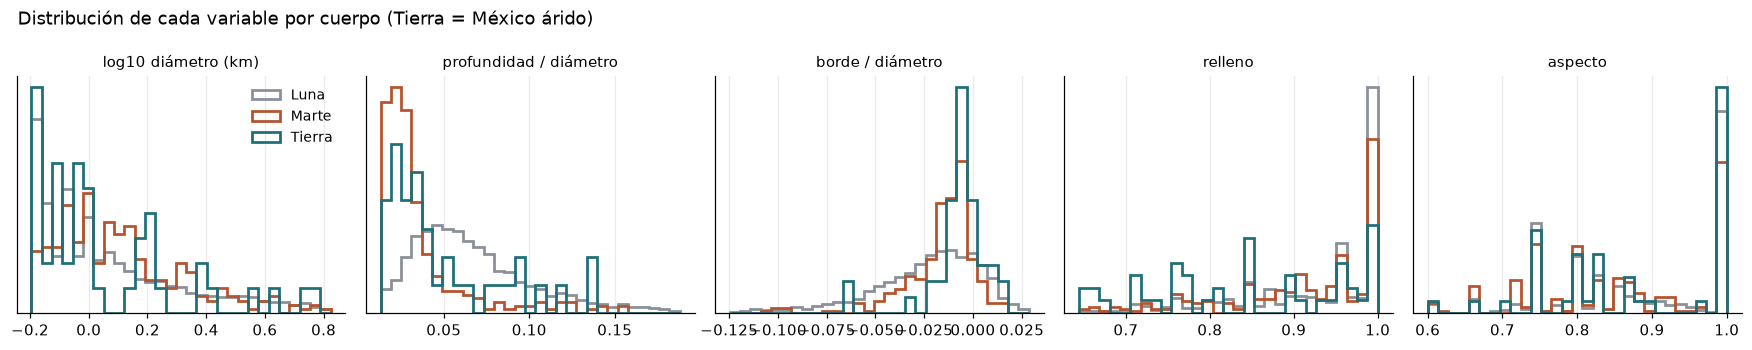

In [5]:
fig, axs = plt.subplots(1, len(FEATS), figsize=(16, 3.2))
for ax, f in zip(axs, FEATS):
    lo, hi = np.nanpercentile(datos[f], [1, 99])
    bins = np.linspace(lo, hi, 30)
    for c in ["Luna", "Marte", "Tierra"]:
        ax.hist(datos.loc[datos.cuerpo == c, f], bins=bins, density=True, histtype="step", lw=1.8, color=COLORES[c], label=c)
    ax.set_title(NOMBRES[f], fontsize=10); ax.set_yticks([])
axs[0].legend(frameon=False, fontsize=9)
fig.suptitle("Distribución de cada variable por cuerpo (Tierra = México árido)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(SALIDA / "distribuciones.png", bbox_inches="tight"); plt.show()

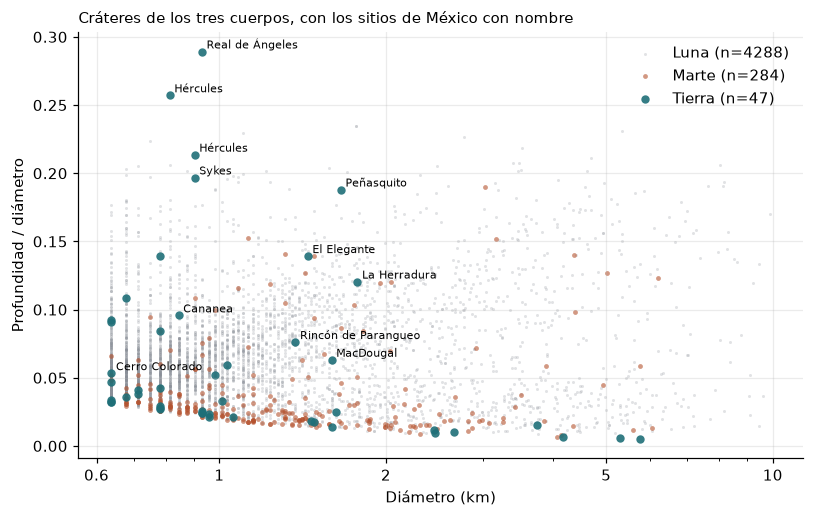

In [6]:
# El plano clásico: diámetro contra profundidad/diámetro
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for c, s, a in [("Luna", 4, .25), ("Marte", 10, .6), ("Tierra", 30, .9)]:
    d = datos[datos.cuerpo == c]
    ax.scatter(10 ** d.log_diam, d.prof_diam, s=s, alpha=a, color=COLORES[c], lw=0, label=f"{c} (n={len(d)})")
nom = datos[datos.nombre.notna()]
for _, p in nom.iterrows():
    ax.annotate(p.nombre.split(" (")[0], (10 ** p.log_diam, p.prof_diam), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("Diámetro (km)"); ax.set_ylabel("Profundidad / diámetro")
ax.set_xticks([0.6, 1, 2, 5, 10]); ax.set_xticklabels(["0.6", "1", "2", "5", "10"])
ax.legend(frameon=False); ax.set_title("Cráteres de los tres cuerpos, con los sitios de México con nombre", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(SALIDA / "diam_vs_dD.png", bbox_inches="tight"); plt.show()

### El problema de las zonas húmedas, en números

Si las detecciones en zonas de mucha vegetación (que coinciden con sierras kársticas y terreno disectado) fueran cráteres, deberían parecerse a las de zonas áridas. Comparamos las tres franjas de vegetación de México.

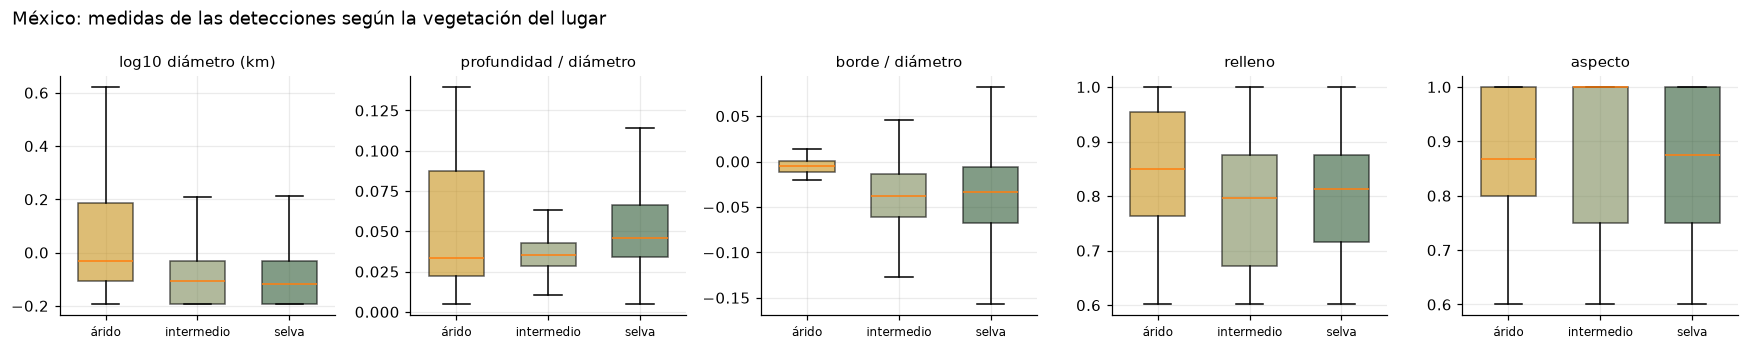

            log_diam  prof_diam  borde_rel  relleno  aspecto
entorno                                                     
árido         -0.031      0.034     -0.005    0.849    0.867
intermedio    -0.107      0.035     -0.038    0.796    1.000
selva         -0.116      0.046     -0.034    0.813    0.875


In [7]:
fig, axs = plt.subplots(1, len(FEATS), figsize=(16, 3.2))
col_ent = {"árido": "#c7921a", "intermedio": "#7d8b5a", "selva": "#2f5b35"}
for ax, f in zip(axs, FEATS):
    vals = [m.loc[m.entorno == e, f].dropna() for e in col_ent]
    bp = ax.boxplot(vals, tick_labels=list(col_ent), patch_artist=True, showfliers=False, widths=.6)
    for patch, c in zip(bp["boxes"], col_ent.values()):
        patch.set_facecolor(c); patch.set_alpha(.6)
    ax.set_title(NOMBRES[f], fontsize=10); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("México: medidas de las detecciones según la vegetación del lugar", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(SALIDA / "mexico_por_entorno.png", bbox_inches="tight"); plt.show()
print(m.groupby("entorno", observed=True)[FEATS].median().round(3).to_string())

## 3. Validación honesta

- **Grupos espaciales** (`StratifiedGroupKFold`): un bloque de ~50 km entero va a prueba o a entrenamiento, nunca partido. Si no, el modelo "ve" cráteres vecinos casi idénticos y la exactitud sale inflada.
- **Exactitud balanceada**: promedio del acierto por clase. Con 4,288 cráteres lunares, decir "Luna" siempre da 92 % de exactitud normal y no sirve de nada; la exactitud balanceada de eso es 33 %.
- **Pesos por clase** (`class_weight="balanced"`) para que la Tierra cuente aunque tenga 47 casos.
- Las predicciones que usamos después son **fuera de pliegue**: a cada cráter lo califica un modelo que no lo vio.

In [8]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
CLASES = ["Luna", "Marte", "Tierra"]

def evaluar(modelo, X, y, g, nombre):
    p = cross_val_predict(modelo, X, y, groups=g, cv=cv, method="predict_proba")
    pred = np.array(CLASES)[p.argmax(1)]
    return {"modelo": nombre, "exactitud_balanceada": balanced_accuracy_score(y, pred),
            **{f"recall_{c}": (pred[y == c] == c).mean() for c in CLASES}}, p, pred

modelos = {
    "Línea base (al azar, proporcional)": DummyClassifier(strategy="stratified", random_state=SEMILLA),
    "Árbol profundidad 2": DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=SEMILLA),
    "Árbol profundidad 3": DecisionTreeClassifier(max_depth=3, class_weight="balanced", min_samples_leaf=5, random_state=SEMILLA),
    "Árbol profundidad 5": DecisionTreeClassifier(max_depth=5, class_weight="balanced", min_samples_leaf=5, random_state=SEMILLA),
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
}
res, probs, preds = [], {}, {}
for n, mod in modelos.items():
    fila, probs[n], preds[n] = evaluar(mod, X, y, g, n)
    res.append(fila)
tabla = pd.DataFrame(res).set_index("modelo")
print((tabla * 100).round(0).astype(int).astype(str).add(" %").to_string())

                                   exactitud_balanceada recall_Luna recall_Marte recall_Tierra
modelo                                                                                        
Línea base (al azar, proporcional)                 32 %        92 %          5 %           0 %
Árbol profundidad 2                                49 %        50 %         52 %          45 %
Árbol profundidad 3                                51 %        63 %         57 %          32 %
Árbol profundidad 5                                52 %        70 %         65 %          21 %
Regresión logística                                55 %        52 %         67 %          47 %


## 4. El árbol de decisión

Elegimos profundidad 3: se puede dibujar y leer, y en la tabla de arriba se ve si ganar profundidad mejora de verdad o solo memoriza. Lo entrenamos con todos los datos para dibujarlo (la exactitud ya la medimos fuera de pliegue).

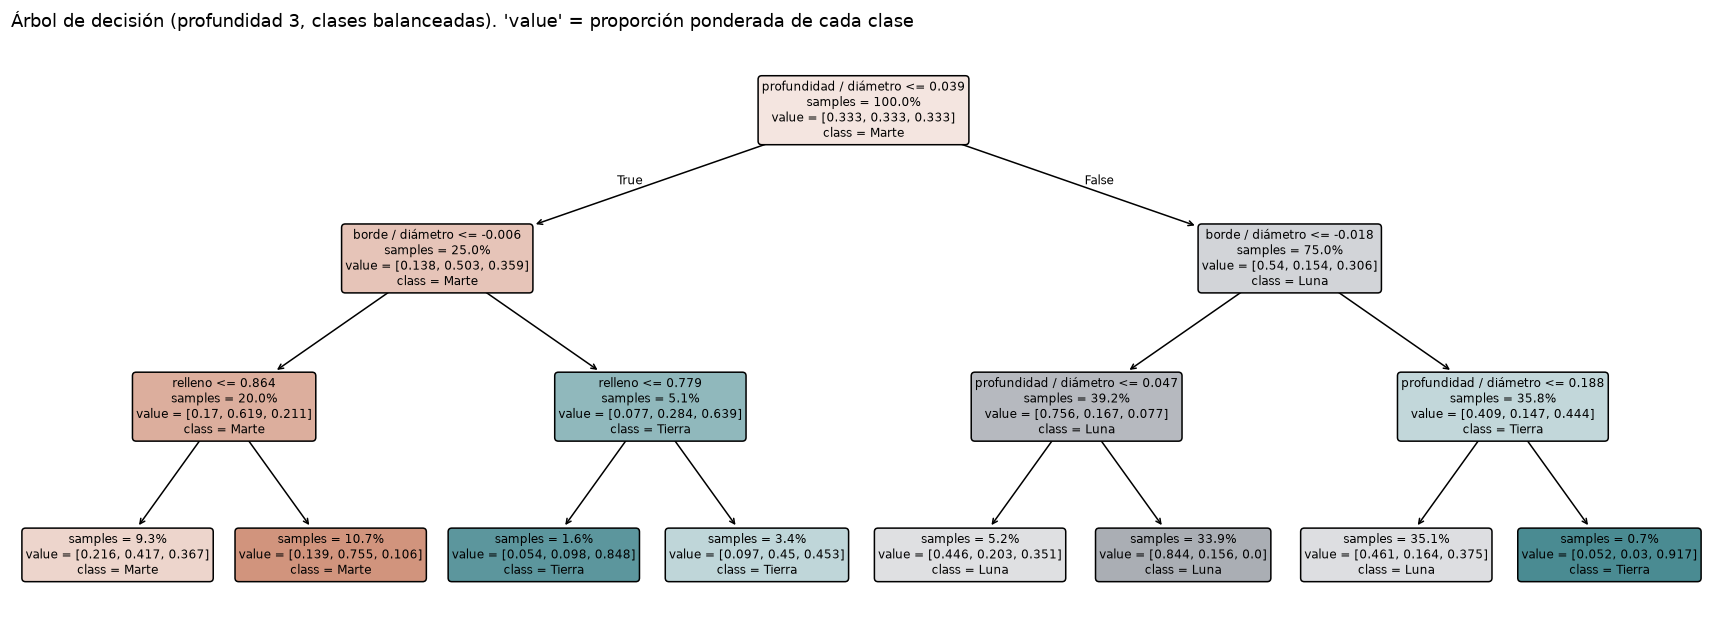

|--- prof_diam <= 0.039
|   |--- borde_rel <= -0.006
|   |   |--- relleno <= 0.864
|   |   |   |--- class: Marte
|   |   |--- relleno >  0.864
|   |   |   |--- class: Marte
|   |--- borde_rel >  -0.006
|   |   |--- relleno <= 0.779
|   |   |   |--- class: Tierra
|   |   |--- relleno >  0.779
|   |   |   |--- class: Tierra
|--- prof_diam >  0.039
|   |--- borde_rel <= -0.018
|   |   |--- prof_diam <= 0.047
|   |   |   |--- class: Luna
|   |   |--- prof_diam >  0.047
|   |   |   |--- class: Luna
|   |--- borde_rel >  -0.018
|   |   |--- prof_diam <= 0.188
|   |   |   |--- class: Luna
|   |   |--- prof_diam >  0.188
|   |   |   |--- class: Tierra



In [9]:
arbol = DecisionTreeClassifier(max_depth=3, class_weight="balanced", min_samples_leaf=5, random_state=SEMILLA).fit(X, y)
fig, ax = plt.subplots(figsize=(20, 7))
anots = plot_tree(arbol, feature_names=[NOMBRES[f] for f in FEATS], class_names=list(arbol.classes_), filled=True, rounded=True,
                  impurity=False, proportion=True, fontsize=8, ax=ax)
from matplotlib.colors import to_rgba
for a in anots:                                   # colores del proyecto: intensidad = qué tan segura es la hoja
    t = a.get_text()
    if "class = " in t and a.get_bbox_patch() is not None:
        c = t.split("class = ")[1].strip()
        v = [float(x) for x in t.split("value = [")[1].split("]")[0].split(",")]
        k = 0.15 + 0.75 * (max(v) - 1/3) / (2/3)          # mezcla opaca con blanco para que las flechas no se vean a través
        a.get_bbox_patch().set_facecolor(tuple(1 - k + k * ch for ch in to_rgba(COLORES[c])[:3]))
ax.set_title("Árbol de decisión (profundidad 3, clases balanceadas). 'value' = proporción ponderada de cada clase", loc="left")
fig.savefig(SALIDA / "arbol.png", bbox_inches="tight"); plt.show()
print(export_text(arbol, feature_names=FEATS, decimals=3))

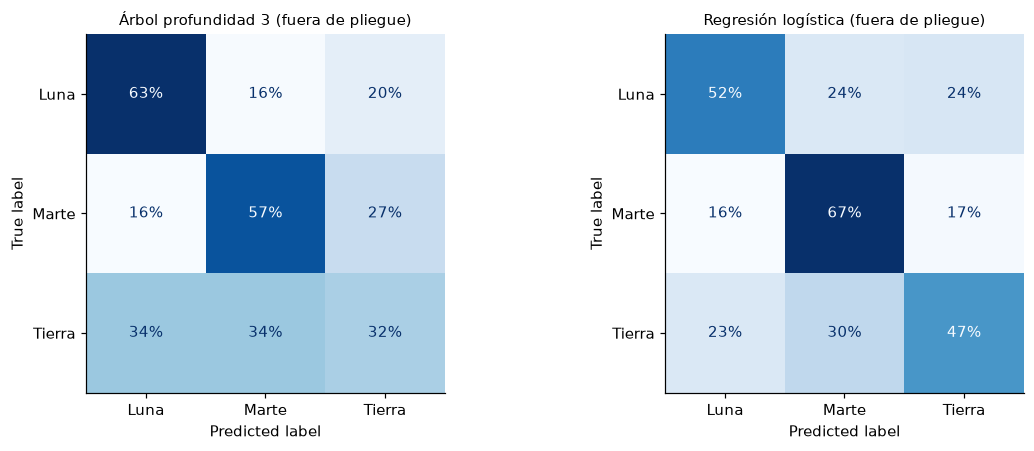

              precision    recall  f1-score   support

        Luna       0.98      0.63      0.77      4288
       Marte       0.19      0.57      0.28       284
      Tierra       0.02      0.32      0.03        47

    accuracy                           0.63      4619
   macro avg       0.39      0.51      0.36      4619
weighted avg       0.92      0.63      0.73      4619



In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, n in zip(axs, ["Árbol profundidad 3", "Regresión logística"]):
    ConfusionMatrixDisplay(confusion_matrix(y, preds[n], labels=CLASES, normalize="true"), display_labels=CLASES).plot(
        ax=ax, cmap="Blues", values_format=".0%", colorbar=False)
    ax.set_title(n + " (fuera de pliegue)", fontsize=10); ax.grid(False)
fig.tight_layout(); fig.savefig(SALIDA / "confusion.png", bbox_inches="tight"); plt.show()
print(classification_report(y, preds["Árbol profundidad 3"], labels=CLASES, zero_division=0))

### ¿Qué variable pesa más?

Dos miradas: la importancia interna del árbol y la **importancia por permutación** (cuánto empeora la exactitud balanceada si revolvemos una variable). La segunda es más confiable porque no favorece a las variables con muchos cortes posibles. Para la regresión logística mostramos sus coeficientes (variables estandarizadas): signo y tamaño dicen hacia qué cuerpo empuja cada rasgo.

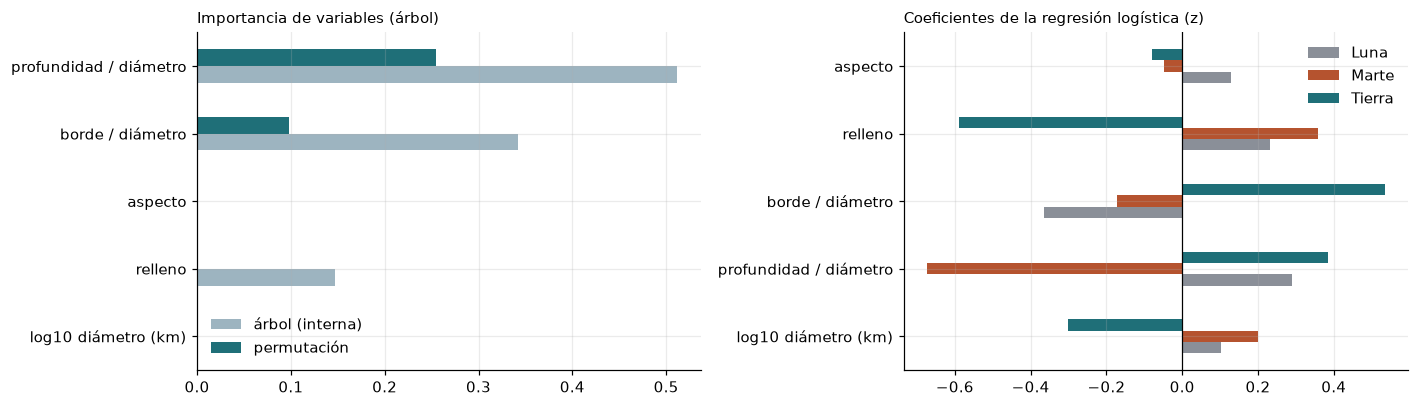

                        árbol (interna)  permutación
log10 diámetro (km)               0.000        0.000
profundidad / diámetro            0.512        0.255
borde / diámetro                  0.342        0.098
relleno                           0.147        0.000
aspecto                           0.000        0.000

                        Luna  Marte  Tierra
log10 diámetro (km)     0.10   0.20   -0.30
profundidad / diámetro  0.29  -0.67    0.38
borde / diámetro       -0.36  -0.17    0.54
relleno                 0.23   0.36   -0.59
aspecto                 0.13  -0.05   -0.08


In [11]:
perm = permutation_importance(arbol, X, y, scoring="balanced_accuracy", n_repeats=20, random_state=SEMILLA)
imp = pd.DataFrame({"árbol (interna)": arbol.feature_importances_, "permutación": perm.importances_mean}, index=[NOMBRES[f] for f in FEATS])
log = modelos["Regresión logística"].fit(X, y)
coef = pd.DataFrame(log[-1].coef_.T, index=[NOMBRES[f] for f in FEATS], columns=log[-1].classes_)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
imp.sort_values("permutación").plot.barh(ax=axs[0], color=["#9db4c0", "#1f6f78"])
axs[0].set_title("Importancia de variables (árbol)", loc="left", fontsize=10); axs[0].legend(frameon=False)
coef.plot.barh(ax=axs[1], color=[COLORES[c] for c in coef.columns])
axs[1].axvline(0, color="k", lw=.8); axs[1].set_title("Coeficientes de la regresión logística (z)", loc="left", fontsize=10)
axs[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(SALIDA / "importancias.png", bbox_inches="tight"); plt.show()
print(imp.round(3).to_string()); print(); print(coef.round(2).to_string())

### Cómo corta el modelo el plano diámetro–d/D

Un árbol solo con las dos variables más famosas, para ver las fronteras de decisión dibujadas sobre los datos.

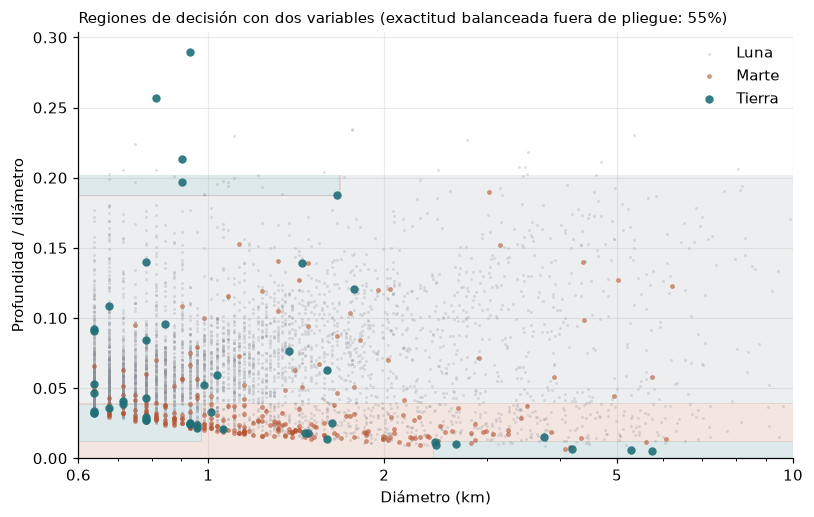

In [12]:
X2 = datos[["log_diam", "prof_diam"]].to_numpy(float)
a2 = DecisionTreeClassifier(max_depth=3, class_weight="balanced", min_samples_leaf=5, random_state=SEMILLA).fit(X2, y)
xx, yy = np.meshgrid(np.linspace(np.log10(0.6), 1, 300), np.linspace(0, datos.prof_diam.quantile(.995), 300))
zz = pd.Series(a2.predict(np.c_[xx.ravel(), yy.ravel()])).map({c: i for i, c in enumerate(CLASES)}).values.reshape(xx.shape)
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.contourf(10 ** xx, yy, zz, levels=[-.5, .5, 1.5, 2.5], cmap=ListedColormap([COLORES[c] for c in CLASES]), alpha=.15)
for c, s, a in [("Luna", 4, .25), ("Marte", 10, .6), ("Tierra", 30, .9)]:
    d = datos[datos.cuerpo == c]; ax.scatter(10 ** d.log_diam, d.prof_diam, s=s, alpha=a, color=COLORES[c], lw=0, label=c)
ax.set_xscale("log"); ax.set_xticks([0.6, 1, 2, 5, 10]); ax.set_xticklabels(["0.6", "1", "2", "5", "10"])
ax.set_xlabel("Diámetro (km)"); ax.set_ylabel("Profundidad / diámetro"); ax.legend(frameon=False)
ax.set_title(f"Regiones de decisión con dos variables (exactitud balanceada fuera de pliegue: "
             f"{balanced_accuracy_score(y, cross_val_predict(a2, X2, y, groups=g, cv=cv)):.0%})", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(SALIDA / "regiones.png", bbox_inches="tight"); plt.show()

## 5. Experimento de control: ¿qué pasa si usamos las 668 detecciones?

Si entrenamos con todo México (incluida la selva), el modelo aprende a reconocer "dolina o cañada de sierra húmeda" y no "cráter terrestre". Lo comprobamos: entrenamos así y miramos qué tanto acierta con las detecciones áridas, que son las que nos interesan.

In [13]:
datos_todo = pd.concat([r[cols], m[cols + ["entorno"]]], ignore_index=True)
Xt = datos_todo[FEATS].to_numpy(float); yt = datos_todo.cuerpo.to_numpy(object); gt = datos_todo.grupo.to_numpy(object)
arbol_t = DecisionTreeClassifier(max_depth=3, class_weight="balanced", min_samples_leaf=5, random_state=SEMILLA)
pt = cross_val_predict(arbol_t, Xt, yt, groups=gt, cv=cv, method="predict_proba")
pred_t = np.array(CLASES)[pt.argmax(1)]
ent = datos_todo.entorno.astype(str).to_numpy(object)
print(f"Exactitud balanceada global: {balanced_accuracy_score(yt, pred_t):.0%}")
for e in ["selva", "intermedio", "árido"]:
    s = ent == e; print(f"  México {e:10s} (n={s.sum():3d}): clasificado como Tierra {np.mean(pred_t[s] == 'Tierra'):.0%}")
arbol_t.fit(Xt, yt)
print("\nReglas aprendidas con las 668:"); print(export_text(arbol_t, feature_names=FEATS, decimals=3))

Exactitud balanceada global: 66%
  México selva      (n=472): clasificado como Tierra 60%
  México intermedio (n=149): clasificado como Tierra 65%
  México árido      (n= 47): clasificado como Tierra 28%

Reglas aprendidas con las 668:
|--- prof_diam <= 0.032
|   |--- relleno <= 0.861
|   |   |--- prof_diam <= 0.022
|   |   |   |--- class: Marte
|   |   |--- prof_diam >  0.022
|   |   |   |--- class: Tierra
|   |--- relleno >  0.861
|   |   |--- borde_rel <= -0.041
|   |   |   |--- class: Tierra
|   |   |--- borde_rel >  -0.041
|   |   |   |--- class: Marte
|--- prof_diam >  0.032
|   |--- relleno <= 0.850
|   |   |--- log_diam <= -0.002
|   |   |   |--- class: Tierra
|   |   |--- log_diam >  -0.002
|   |   |   |--- class: Luna
|   |--- relleno >  0.850
|   |   |--- prof_diam <= 0.045
|   |   |   |--- class: Marte
|   |   |--- prof_diam >  0.045
|   |   |   |--- class: Luna



## 6. Puntaje de análogo para México

Para cada cráter árido de México, la probabilidad **fuera de pliegue** de que el árbol y la regresión logística lo tomen por lunar o marciano. Si un cráter terrestre "engaña" al modelo, es que su forma está dentro de lo que se ve en la Luna o Marte con estas medidas. Ojo: es un puntaje de forma, no de composición, temperatura ni gravedad.

In [14]:
es_mx = y == "Tierra"
pa, pl = probs["Árbol profundidad 3"], probs["Regresión logística"]
punt = datos.loc[es_mx, ["cid", "nombre", "tipo"]].copy()
punt["diam_km"] = (10 ** datos.loc[es_mx, "log_diam"]).round(2)
punt["d/D"] = datos.loc[es_mx, "prof_diam"].round(3)
for nom, p in [("árbol", pa), ("logística", pl)]:
    punt[f"P_Luna_{nom}"] = p[es_mx, 0].round(2); punt[f"P_Marte_{nom}"] = p[es_mx, 1].round(2)
punt["análogo"] = ((punt.P_Luna_logística + punt.P_Marte_logística + punt.P_Luna_árbol + punt.P_Marte_árbol) / 2).round(2)
punt = punt.sort_values("análogo", ascending=False)
punt.to_csv(SALIDA / "puntaje_analogo_mexico.csv", index=False)
print("Cráteres áridos de México que el modelo confunde con Luna o Marte (1 = siempre, 0 = nunca):")
print(punt.head(15).to_string(index=False))
print("\nPromedio por tipo:"); print(punt.groupby("tipo").análogo.agg(["size", "mean"]).round(2).to_string())

Cráteres áridos de México que el modelo confunde con Luna o Marte (1 = siempre, 0 = nunca):
   cid                 nombre      tipo  diam_km   d/D  P_Luna_árbol  P_Marte_árbol  P_Luna_logística  P_Marte_logística  análogo
MX0016                    NaN sin_borde     0.64 0.047          0.73           0.27              0.64               0.36     1.00
MX0015                    NaN sin_borde     0.71 0.041          0.73           0.27              0.61               0.37     0.99
MX0121                    NaN sin_borde     5.29 0.006          0.19           0.77              0.16               0.81     0.97
MX0207 Real de Ángeles (Zac.)      mina     0.93 0.289          0.76           0.24              0.86               0.00     0.93
MX0007   MacDougal (Pinacate) sin_borde     1.60 0.063          0.74           0.20              0.54               0.36     0.92
MX0018                    NaN sin_borde     0.68 0.036          0.17           0.69              0.58               0.37     0.9

In [15]:
# Exportar el árbol para la web (capa "método"): reglas en JSON
def arbol_a_json(t, feats):
    tr = t.tree_
    def nodo(i):
        if tr.children_left[i] == -1:
            v = tr.value[i][0]; v = v / v.sum()
            return {"hoja": True, "clase": str(t.classes_[v.argmax()]), "prob": {str(c): round(float(p), 3) for c, p in zip(t.classes_, v)},
                    "n": int(tr.n_node_samples[i])}
        return {"hoja": False, "variable": feats[tr.feature[i]], "umbral": round(float(tr.threshold[i]), 4), "n": int(tr.n_node_samples[i]),
                "si": nodo(tr.children_left[i]), "no": nodo(tr.children_right[i])}
    return nodo(0)

salida = {"descripcion": "Árbol de profundidad 3 que separa cráteres de Luna, Marte y Tierra (México árido). 'si' = variable <= umbral.",
          "variables": NOMBRES, "exactitud_balanceada_cv": round(float(tabla.loc["Árbol profundidad 3", "exactitud_balanceada"]), 3),
          "arbol": arbol_a_json(arbol, FEATS),
          "importancia_permutacion": {f: round(float(v), 3) for f, v in zip(FEATS, perm.importances_mean)}}
(SALIDA / "arbol.json").write_text(json.dumps(salida, ensure_ascii=False, indent=1))
print("Guardado", SALIDA / "arbol.json")

Guardado /home/mario/spaceapps-2026/ciencia_datos/salidas/arbol.json


## 7. Sensibilidad: ¿cambian las conclusiones con el umbral de NDVI?

El umbral de 0.35 para "árido" es una decisión nuestra. Repetimos la evaluación con otros umbrales.

In [16]:
filas = []
for u in [0.2, 0.25, 0.35, 0.5, 0.7]:
    sel = m.ndvi_p90 < u
    d = pd.concat([r[cols], m.loc[sel, cols]], ignore_index=True)
    mod = DecisionTreeClassifier(max_depth=3, class_weight="balanced", min_samples_leaf=5, random_state=SEMILLA)
    Xd, yd, gd = d[FEATS].to_numpy(float), d.cuerpo.to_numpy(object), d.grupo.to_numpy(object)
    pr = cross_val_predict(mod, Xd, yd, groups=gd, cv=cv)
    mod.fit(Xd, yd)
    raiz = FEATS[mod.tree_.feature[0]]
    filas.append({"NDVI <": u, "n Tierra": int(sel.sum()), "exactitud balanceada": f"{balanced_accuracy_score(yd, pr):.0%}",
                  "recall Tierra": f"{(pr[yd == 'Tierra'] == 'Tierra').mean():.0%}", "primer corte": raiz})
print(pd.DataFrame(filas).to_string(index=False))

 NDVI <  n Tierra exactitud balanceada recall Tierra primer corte
   0.20        25                  47%           28%    prof_diam
   0.25        29                  50%           28%    prof_diam
   0.35        47                  51%           32%    prof_diam
   0.50        85                  59%           39%    prof_diam
   0.70       196                  65%           52%    prof_diam


## Lectura de esta corrida (datos del 14 de noviembre de 2026)

- **Las formas se traslapan mucho.** El mejor modelo (regresión logística) llega a 55 % de exactitud balanceada fuera de pliegue, contra 32 % de la línea base. El árbol de profundidad 3 llega a 51 %. Hay señal, pero un cráter árido de México, a 200 m por píxel, cae casi siempre dentro de lo que se ve en la Luna o en Marte. Para el reto eso es buena noticia: en forma, son análogos creíbles.
- **Profundidad / diámetro es la regla principal** (primer corte del árbol y mayor importancia por permutación). Los cráteres del polo sur lunar son más hondos para su tamaño (mediana d/D 0.060) que los marcianos de Jezero, Gale y Oxia (0.027); México árido queda en medio (0.034). El segundo rasgo es la altura del borde: en México los bordes casi no sobresalen, como se espera de maars, dolinas y tajos mineros.
- **Más profundidad no ayuda.** Pasar de 3 a 5 niveles sube la exactitud balanceada solo 1 punto y baja el acierto en la Tierra de 32 % a 21 %: el árbol empieza a memorizar la Luna.
- **El control confirma el problema de la selva.** Entrenado con las 668 detecciones, el modelo reconoce como Tierra al 60 % de las de selva pero solo al 28 % de las áridas: aprendió la firma de las dolinas y cañadas de las sierras húmedas, no la del cráter terrestre. En la tabla de sensibilidad pasa lo mismo: al subir el umbral de NDVI, la Tierra parece más fácil de separar porque entran más de esas depresiones.
- **Puntaje de análogo.** Las minas (Real de Ángeles, Peñasquito) salen "lunares" por su d/D alto, y MacDougal (Pinacate) también. Los cráteres anchos y planos (por ejemplo MX0121, 5.3 km) salen "marcianos". Con 47 casos ruidosos este puntaje es preliminar.

## 8. Conclusiones y límites

Ver la celda siguiente para los números de esta corrida; la lectura general es:

- **Lo que separa los mundos** son pocas reglas legibles sobre forma (ver árbol e importancias). Eso es material directo para "dónde funciona y dónde se rompe la analogía".
- **La limpieza de datos importa más que el modelo.** Con las 668 detecciones el modelo aprende a reconocer dolinas y cañadas de sierras húmedas. FABDEM no lo resuelve (no es un problema de árboles, sino de terreno), así que el filtro tiene que ser por contexto geológico o por NDVI, y el paso con más impacto es que el equipo etiquete a mano las 47 áridas.
- **Límites:** (1) el detector solo ve cráteres de 0.6 a 10 km y ≥ 20 m de profundidad, así que las reglas valen solo en ese rango; (2) los tres cuerpos se midieron con instrumentos distintos (LOLA, HRSC+MOLA, Copernicus), y parte de la diferencia puede ser del instrumento; (3) la Tierra tiene decenas de casos y la mayoría no son impactos (maars, conos, minas), así que el modelo compara también orígenes distintos; (4) es solo el eje de forma: no dice nada de composición, temperatura, gravedad, vacío ni radiación.

In [17]:
mejor = tabla.exactitud_balanceada.idxmax()
print(f"Mejor modelo fuera de pliegue: {mejor} ({tabla.loc[mejor, 'exactitud_balanceada']:.0%}); "
      f"línea base {tabla.iloc[0].exactitud_balanceada:.0%}; árbol profundidad 3 {tabla.loc['Árbol profundidad 3', 'exactitud_balanceada']:.0%}")
print("Variable más importante (permutación):", imp.permutación.idxmax())
print("Archivos generados:", sorted(p.name for p in SALIDA.iterdir()))

Mejor modelo fuera de pliegue: Regresión logística (55%); línea base 32%; árbol profundidad 3 51%
Variable más importante (permutación): profundidad / diámetro
Archivos generados: ['arbol.json', 'arbol.png', 'confusion.png', 'diam_vs_dD.png', 'distribuciones.png', 'importancias.png', 'mexico_por_entorno.png', 'puntaje_analogo_mexico.csv', 'regiones.png']
